In [1]:
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
from sklearn.model_selection import train_test_split
dataset = pd.read_csv('train-2.csv')

print(dataset.shape)
print(dataset.isna().sum())
dataset.head()

(891, 12)
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:

dict_for_coding = {'male' : 1, 'female' : 0}

dataset['Sex_coding'] = [dict_for_coding[i] for i in dataset['Sex']]
features_for_predict = ['Pclass', 'Sex_coding','Age','Fare',]
X,y = dataset[features_for_predict], dataset['Survived']

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)
age_median = X_train['Age'].median()

X_train = X_train.copy()
X_test = X_test.copy()


X_train['Age'] = X_train['Age'].fillna(age_median)
X_test['Age'] = X_test['Age'].fillna(age_median)


print(X_train.isna().sum())
print(X_test.isna().sum())
print(X_train.shape, X_test.shape)

Pclass        0
Sex_coding    0
Age           0
Fare          0
dtype: int64
Pclass        0
Sex_coding    0
Age           0
Fare          0
dtype: int64
(712, 4) (179, 4)


In [3]:
X_train_mean = X_train.mean(axis =0)
X_train_std = X_train.std(axis = 0)

X_train_mashtab = (X_train - X_train_mean)/X_train_std


X_test_mashtab = (X_test - X_train_mean)/X_train_std

log_reg_model = LogisticRegression()
log_reg_model.fit(X_train_mashtab, y_train)




,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [4]:
log_reg_model_predict  = log_reg_model.predict(X_test_mashtab)

accuracy = accuracy_score(y_test,log_reg_model_predict)
precision = precision_score(y_test,log_reg_model_predict)
recall = recall_score(y_test,log_reg_model_predict)
f1 = f1_score(y_test,log_reg_model_predict)
matrix_conf = confusion_matrix(y_test,log_reg_model_predict)

print(f"Accuracy:  {accuracy}")
print(f"Precision: {precision}")
print(f"Recall:    {recall}")
print(f"F1-Score: {f1}")
print()
print("Матрица ошибок вашей модели:")
print(f"TN: {matrix_conf [0,0]} | FP: {matrix_conf [0,1]}")
print(f"FN: {matrix_conf [1,0]} | TP: {matrix_conf [1,1]}\n")


Accuracy:  0.7932960893854749
Precision: 0.7681159420289855
Recall:    0.7162162162162162
F1-Score: 0.7412587412587412

Матрица ошибок вашей модели:
TN: 89 | FP: 16
FN: 21 | TP: 53



In [5]:
p = log_reg_model.predict_proba(X_test_mashtab)[:, 1]

p03 = []
p05 = []
p08 = []
baseline = []
for i in p:
    if i >= 0.3:
        p03.append(1)
    else:
        p03.append(0)

for i in p:
    if i >= 0.5:
        p05.append(1)
    else:
        p05.append(0)

for i in p:
    if i >= 0.8:
        p08.append(1)
    else:
        p08.append(0)

for i in p:
    if i > 1:
        baseline.append(1)
    else:
        baseline.append(0)



In [6]:
precision03 = precision_score(y_test,p03)
recall03 = recall_score(y_test,p03)

precision05 = precision_score(y_test,p05)
recall05 = recall_score(y_test,p05)

precision08 = precision_score(y_test,p08)
recall08 = recall_score(y_test,p08)


print(f"Precision 0.3: {precision03}")
print(f"Recall 0.3:    {recall03}")


print(f"Precision 0.5: {precision05}")
print(f"Recall 0.5:    {recall05}")

print(f"Precision 0.8: {precision08}")
print(f"Recall 0.8:    {recall08}")

accuracy_baseline = accuracy_score(y_test,baseline)
print(f'Baseline accuracy: {accuracy_baseline}')


Precision 0.3: 0.7096774193548387
Recall 0.3:    0.8918918918918919
Precision 0.5: 0.7681159420289855
Recall 0.5:    0.7162162162162162
Precision 0.8: 0.9666666666666667
Recall 0.8:    0.3918918918918919
Baseline accuracy: 0.5865921787709497


In [7]:
for name, weight in zip(X_train.columns, log_reg_model.coef_[0]):
    print(f"TABLE: {name} : {weight}")
    

TABLE: Pclass : -0.8370846689737713
TABLE: Sex_coding : -1.2109703120564992
TABLE: Age : -0.32659780895964174
TABLE: Fare : 0.05575761077597715


## Вывод: логистическая регрессия на Titanic

**1. Сравнение с baseline.** Accuracy обученной модели 0.793, accuracy baseline («всегда 0») 0.587. Модель обгоняет baseline примерно на 0.21.

**2. Матрица ошибок и метрики (порог 0.5).**

| | Предсказали 0 | Предсказали 1 |
|---|---|---|
| Реально 0 | TN = 89 | FP = 16 |
| Реально 1 | FN = 21 | TP = 53 |

Precision = 0.768, Recall = 0.716, F1 = 0.741.

**3. Влияние порога.** При росте порога с 0.3 до 0.8 precision увеличивался (0.710, 0.768, 0.967), а recall уменьшался (0.892, 0.716, 0.392). Precision растёт, потому что при высоком пороге модель называет «выжил» только тех, в ком очень уверена, и ложных срабатываний (FP) почти не остаётся. Recall падает, потому что часть настоящих выживших получает вероятность ниже порога и попадает в FN.

**4. Выбор порога.** Для задачи «не пропустить выжившего» я бы выбрал порог 0.3: у него самый высокий recall (0.892), то есть меньше всего пропущенных выживших (FN). Цена этого решения: precision снижается до 0.710, то есть больше ложных срабатываний. Порог 0.8 подошёл бы, если бы нельзя было ошибиться в сторону «выжил».

**5. Веса модели** (признаки масштабированы, поэтому веса сравнимы по величине). Больше всего влияет пол: `Sex_coding` = −1.21 (мужчина выживал реже). Затем `Pclass` = −0.84 (чем ниже класс, тем ниже шанс) и `Age` = −0.33 (чем старше, тем ниже шанс). `Fare` = +0.06, влияние очень незначительное, возможно, из-за тесной связи с `Pclass`: `Pclass` забрал на себя часть воздействия `Fare` (это гипотеза). Знаки согласуются с EDA из недели 4.

**6. Ограничения.** Пропуски в `Age` заполнены медианой по X_train, использованы четыре признака, значения получены на одном разбиении train/test.

In [8]:

dataset1 = pd.read_csv('test-selected-columns.csv')

print(dataset1.shape)
print(dataset1.isna().sum())
dataset1.head()


(418, 10)
PassengerId      0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
dtype: int64


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN


In [9]:
sex_for_coding = {'male' : 1, 'female' : 0}
dataset1['Sex_coding'] = [sex_for_coding[i] for i in dataset1['Sex']]
features_for_predict = ['Pclass', 'Sex_coding','Age','Fare']
age_median = X_train['Age'].median()
dataset1['Age'] = dataset1['Age'].fillna(age_median)

dataset1['Fare'] = dataset1['Fare'].fillna(X_train['Fare'].median())


dataset_mashtab = (dataset1[features_for_predict] - X_train_mean)/X_train_std
print(dataset_mashtab.head())
survived = log_reg_model.predict(dataset_mashtab)

dataset1['Survived'] = survived



     Pclass  Sex_coding       Age      Fare
0  0.812463    0.723801  0.407125 -0.476377
1  0.812463   -1.379654  1.368074 -0.492332
2 -0.400270    0.723801  2.521213 -0.440619
3  0.812463    0.723801 -0.169445 -0.460342
4  0.812463   -1.379654 -0.553824 -0.390590


In [10]:
dataset1[['PassengerId','Survived']].to_csv('submission.csv', index=False)

In [11]:
submission = pd.read_csv('submission.csv')
print(submission.shape)
print(submission['Survived'].value_counts())
print(submission['PassengerId'].min(), submission['PassengerId'].max())

(418, 2)
Survived
0    264
1    154
Name: count, dtype: int64
892 1309


0.8745173745173744


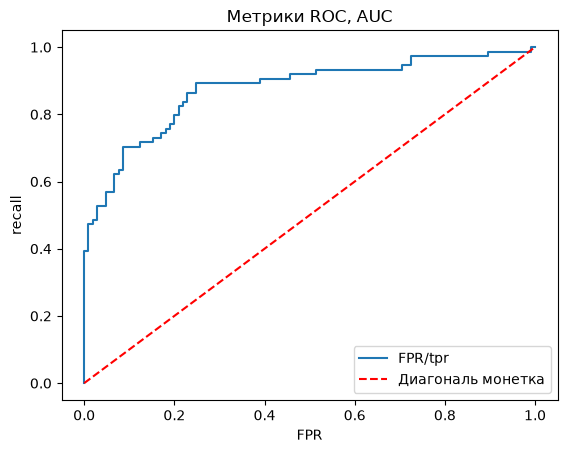

In [12]:
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

roc_auc = roc_auc_score(y_test, p)
print(roc_auc)


fig, ax = plt.subplots()
fpr,tpr,thresholds = roc_curve(y_test, p)
ax.plot(fpr,tpr, label = 'FPR/tpr')

ax.set_xlabel('FPR')
ax.plot([0, 1],[0, 1],linestyle='--',label = 'Диагональ монетка', color = 'red')
ax.set_ylabel('recall')
ax.set_title('Метрики ROC, AUC')
ax.legend()
plt.show()

**Markdown вывод**
## Вывод: ROC-кривая и AUC

**1. ROC-AUC = 0.8745.** Значение 0.5 соответствует монетке, значение 1.0 идеальной модели. У моей модели 0.87, то есть она ближе к идеальной, чем к монетке. Смысл: с вероятностью около 87% случайно выбранный выживший получает от модели вероятность выше, чем случайно выбранный погибший.

**2. Как читать график.**
- Левый верхний угол соответствует идеальной модели: все «1» найдены (TPR = 1) без ложных тревог (FPR = 0). Моя кривая идёт выше диагонали и близко к этому углу.
- Крутой подъём в самом начале (FPR около 0, TPR около 0.4) означает, что самые уверенные предсказания модели почти не ошибаются.
- Каждая ступенька кривой соответствует одному порогу. Порогу 0.5 соответствует точка с recall 0.716 и FPR = 16 / 105 ≈ 0.15, она лежит на кривой.

**3. Отличие от accuracy.** AUC не зависит от выбранного порога и оценивает качество вероятностей. Accuracy считается при одном выбранном пороге.

**4. Выбор порога.** AUC недостаточно, чтобы выбрать порог: он не говорит, какая ошибка дороже. Порог нужно выбирать по цене ошибок (FN или FP).

